In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/delivery-logistics-dataset/Delivery_Logistics.csv


# Delivery Logistics: EDA & Classification Analysis

## Introduction & Objective

In this notebook, we will analyze a delivery logistics dataset. The main goal is to understand the relationships between delivery partners, vehicle types, and delivery performance. Finally, we will build Machine Learning models (LightGBM and XGBoost) to predict the Delivery Rating group based on delivery characteristics.

**Notebook Content:**

**Data Loading & Preprocessing:** Cleaning data and handling missing values.

**Exploratory Data Analysis (EDA):** Visualizing distributions and relationships using Matplotlib, Seaborn, and Plotly.

**Feature Engineering:** Creating target classes for ratings.

**Machine Learning:** Building Classification models.

**Evaluation:** Assessing model performance with Confusion Matrix and Classification Reports.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix

import warnings
warnings.filterwarnings('ignore')

# Set style for plots
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

In [3]:
df = pd.read_csv('/kaggle/input/delivery-logistics-dataset/Delivery_Logistics.csv')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   delivery_id          25000 non-null  float64
 1   delivery_partner     25000 non-null  object 
 2   package_type         25000 non-null  object 
 3   vehicle_type         25000 non-null  object 
 4   delivery_mode        25000 non-null  object 
 5   region               25000 non-null  object 
 6   weather_condition    25000 non-null  object 
 7   distance_km          25000 non-null  float64
 8   package_weight_kg    25000 non-null  float64
 9   delivery_time_hours  25000 non-null  object 
 10  expected_time_hours  25000 non-null  object 
 11  delayed              25000 non-null  object 
 12  delivery_status      25000 non-null  object 
 13  delivery_rating      25000 non-null  int64  
 14  delivery_cost        25000 non-null  float64
dtypes: float64(4), int64(1), object(10)


In [5]:
df.isnull().sum()

delivery_id            0
delivery_partner       0
package_type           0
vehicle_type           0
delivery_mode          0
region                 0
weather_condition      0
distance_km            0
package_weight_kg      0
delivery_time_hours    0
expected_time_hours    0
delayed                0
delivery_status        0
delivery_rating        0
delivery_cost          0
dtype: int64

In [6]:
df.describe()

,delivery_id,distance_km,package_weight_kg,delivery_rating,delivery_cost
count,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000
mean,12500.500000,150.390436,25.145898,3.666000,864.944579
std,7212.732314,86.409745,14.368663,1.149964,435.712593
min,250.990000,3.600000,0.670000,1.000000,95.667400
25%,6250.750000,75.900000,12.680000,3.000000,490.800000
50%,12500.500000,151.000000,25.145000,4.000000,867.535000
75%,18750.250000,224.900000,37.660000,5.000000,1237.910000
max,24750.010000,297.100000,49.520000,5.000000,1632.720600


In [7]:
df.head()

,delivery_id,delivery_partner,package_type,vehicle_type,delivery_mode,region,weather_condition,distance_km,package_weight_kg,delivery_time_hours,expected_time_hours,delayed,delivery_status,delivery_rating,delivery_cost
0,250.99,delhivery,automobile parts,bike,same day,west,clear,297.0,46.96,1970-01-01 00:00:00.000000008,1970-01-01 00:00:00.000000008,no,delivered,3,1632.7206
1,250.99,xpressbees,cosmetics,ev van,express,central,cold,89.6,47.39,1970-01-01 00:00:00.000000002,1970-01-01 00:00:00.000000003,no,delivered,5,640.1700
2,250.99,shadowfax,groceries,truck,two day,east,rainy,273.5,26.89,1970-01-01 00:00:00.000000010,1970-01-01 00:00:00.000000016,no,delivered,4,1448.1700
3,250.99,dhl,electronics,ev van,same day,east,cold,269.7,12.69,1970-01-01 00:00:00.000000006,1970-01-01 00:00:00.000000008,no,delivered,3,1486.5700
4,250.99,dhl,clothing,van,two day,north,foggy,256.7,37.02,1970-01-01 00:00:00.000000009,1970-01-01 00:00:00.000000016,no,delivered,4,1394.5600


## Dropping Redundant Columns

We will drop IDs and time-specific columns that won't be used for this specific classification task. The delayed column is also removed as it is highly correlated with delivery_status.

In [8]:
cols_to_drop = ["delivery_id", "delivery_time_hours", "expected_time_hours", "delayed"]
df = df.drop(cols_to_drop, axis=1)

# EDA

## Distribution of Delivery Partners

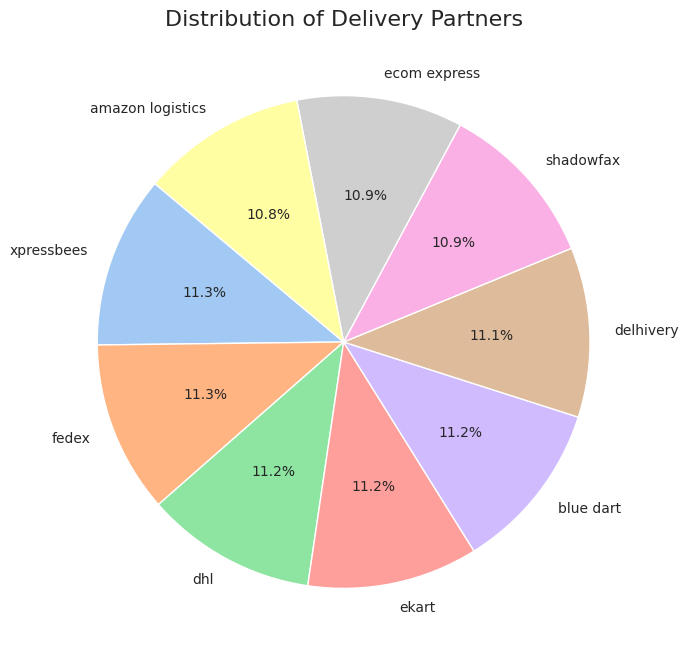

In [9]:
data = df["delivery_partner"].value_counts()
colors = sns.color_palette('pastel')[0:len(data)]

plt.figure(figsize=(8, 8))
plt.pie(data, labels=data.index, colors=colors, autopct='%1.1f%%', startangle=140)
plt.title('Distribution of Delivery Partners', fontsize=16)
plt.show()

## Distribution of Package Types

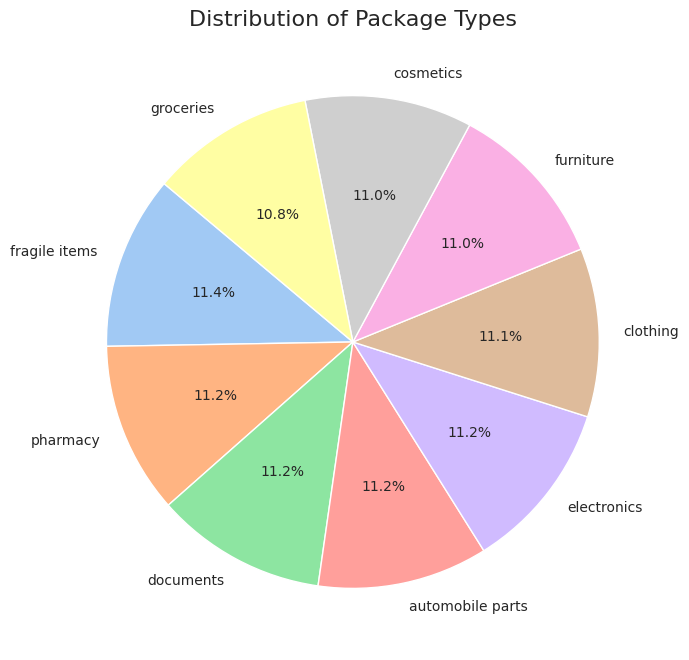

In [10]:
data = df["package_type"].value_counts()
colors = sns.color_palette('pastel')[0:len(data)]

plt.figure(figsize=(8, 8))
plt.pie(data, labels=data.index, colors=colors, autopct='%1.1f%%', startangle=140)
plt.title('Distribution of Package Types', fontsize=16)
plt.show()

## Distribution of Vehicle Types 

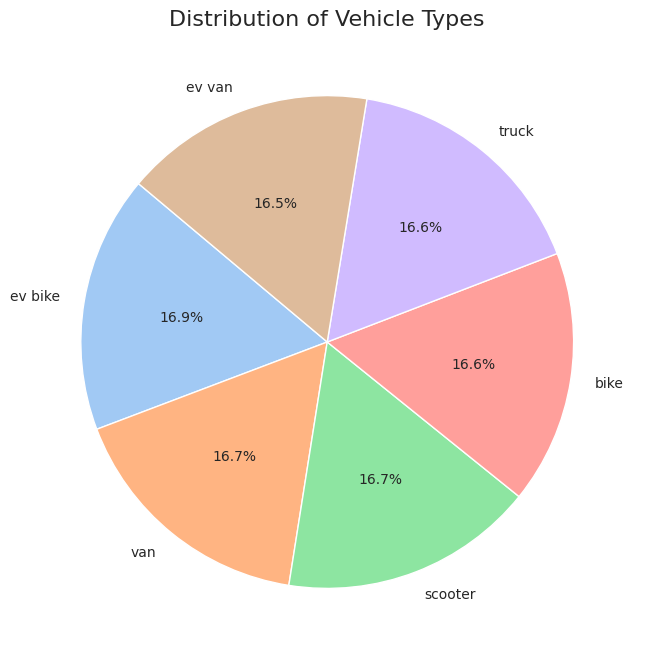

In [11]:
data = df["vehicle_type"].value_counts()
colors = sns.color_palette('pastel')[0:len(data)]

plt.figure(figsize=(8, 8))
plt.pie(data, labels=data.index, colors=colors, autopct='%1.1f%%', startangle=140)
plt.title('Distribution of Vehicle Types', fontsize=16)
plt.show()

## Detailed Analysis by Delivery Partner  

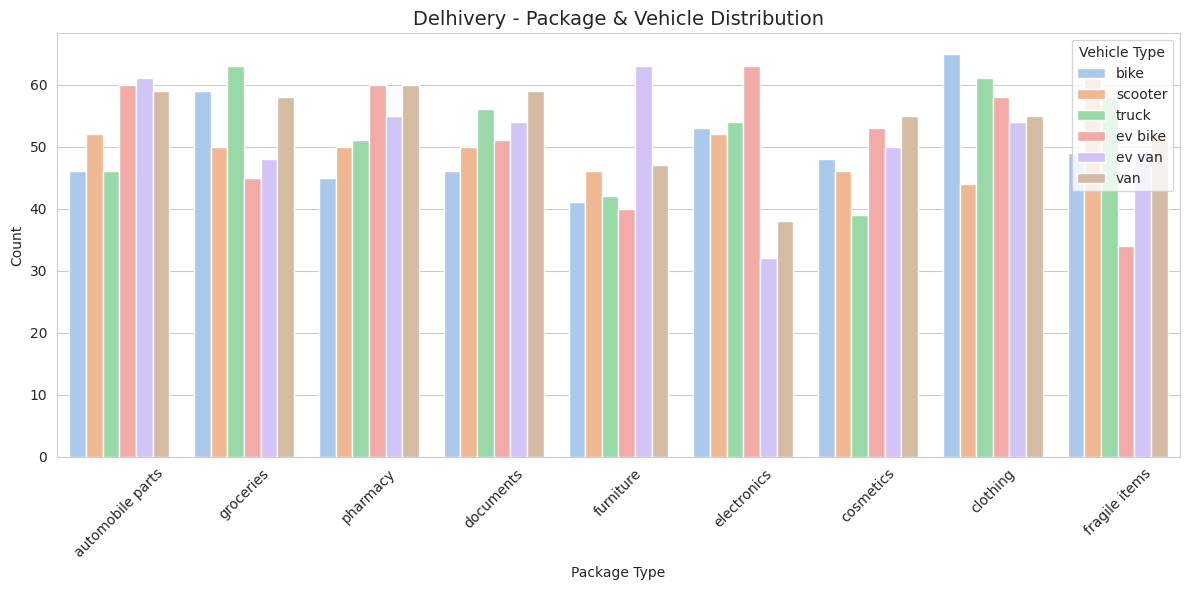

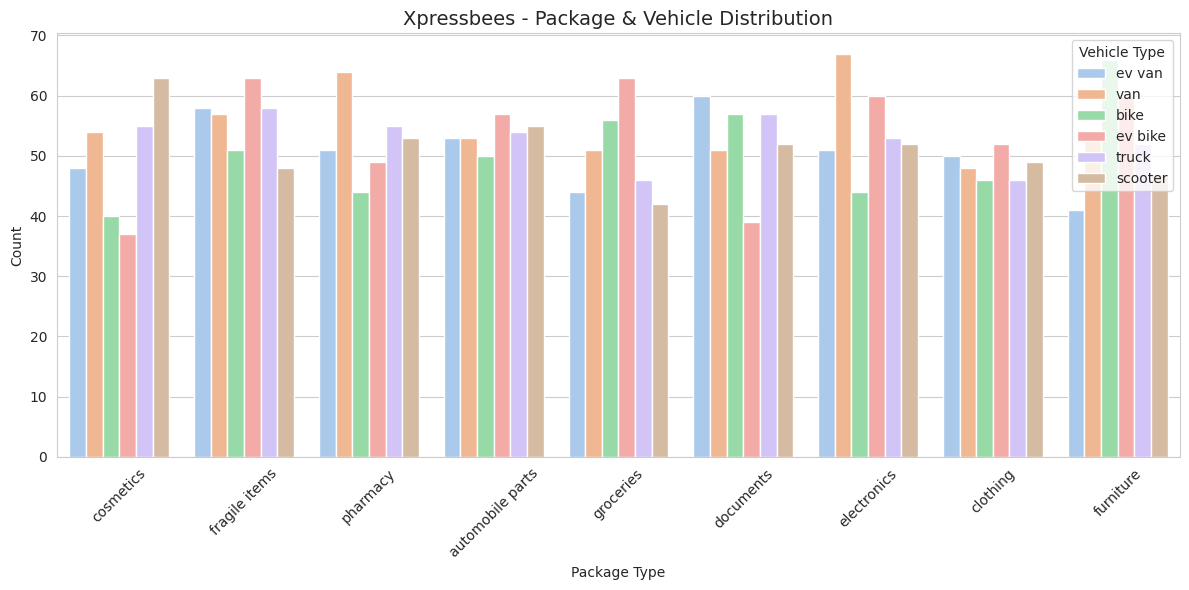

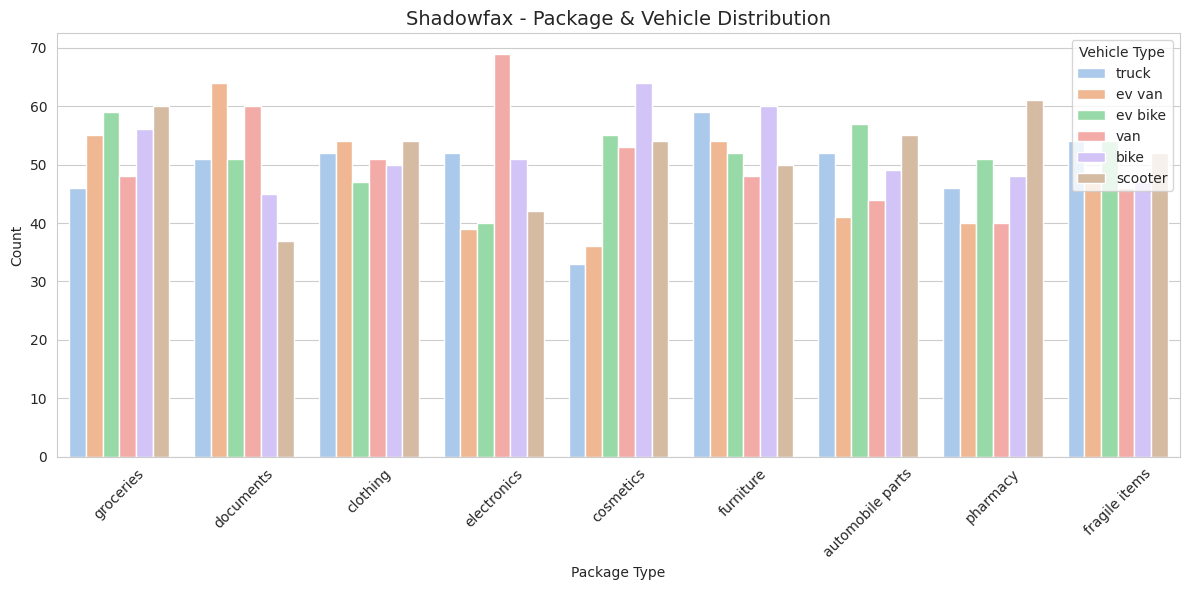

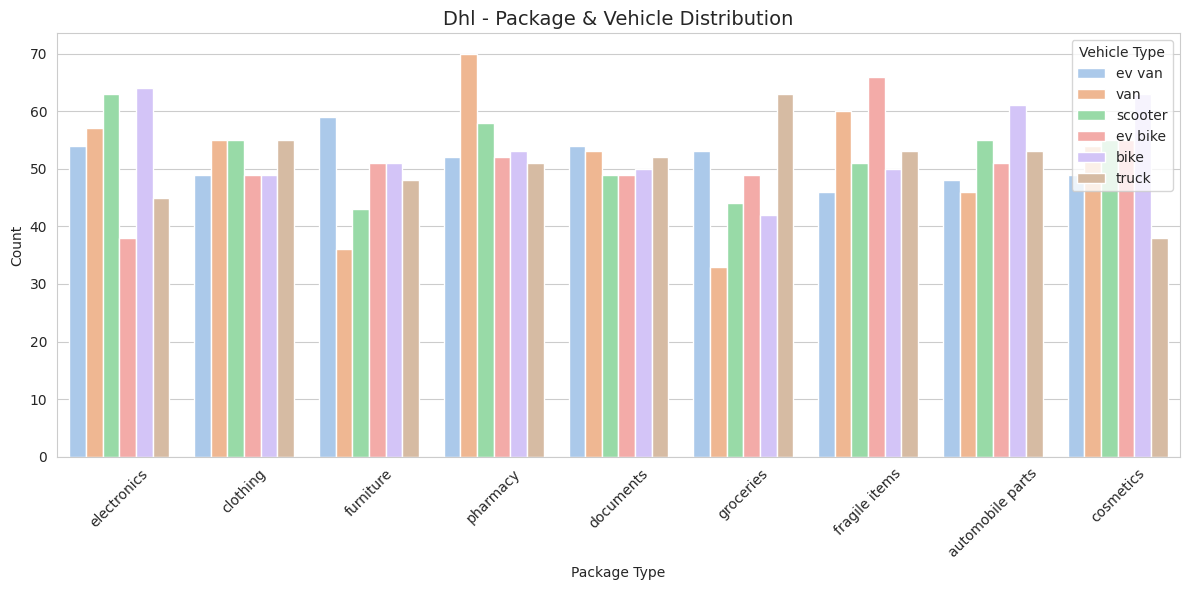

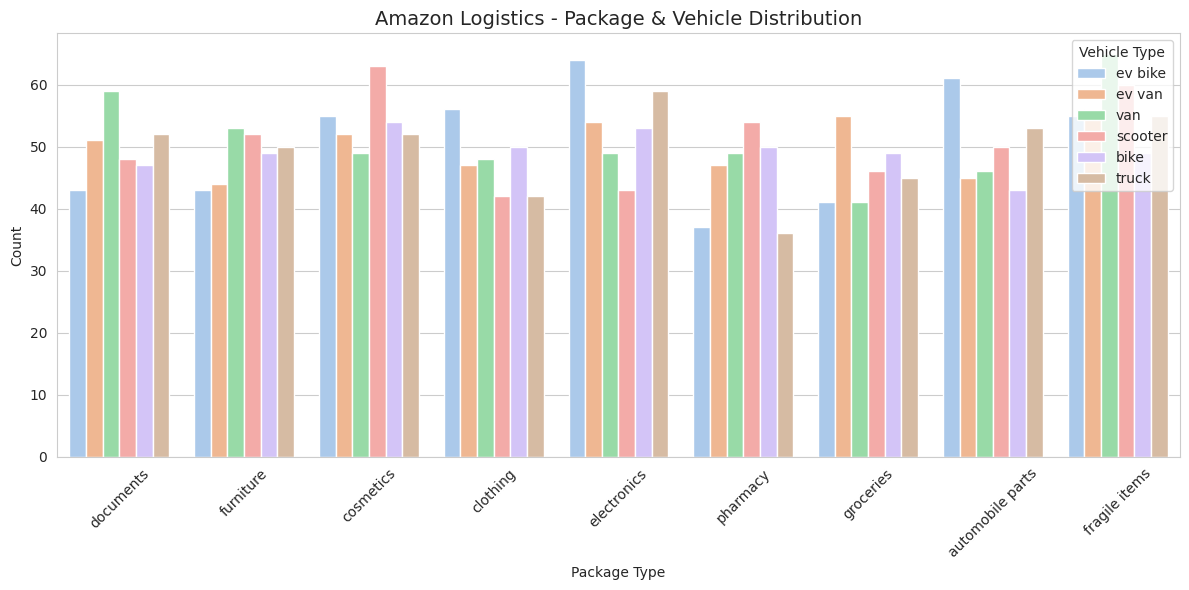

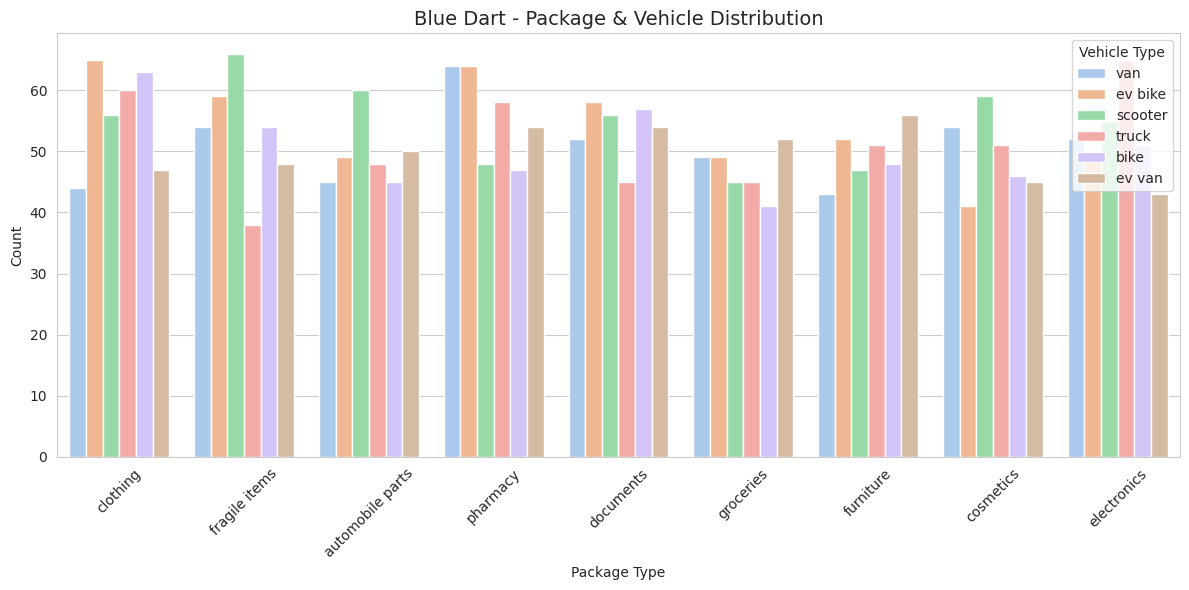

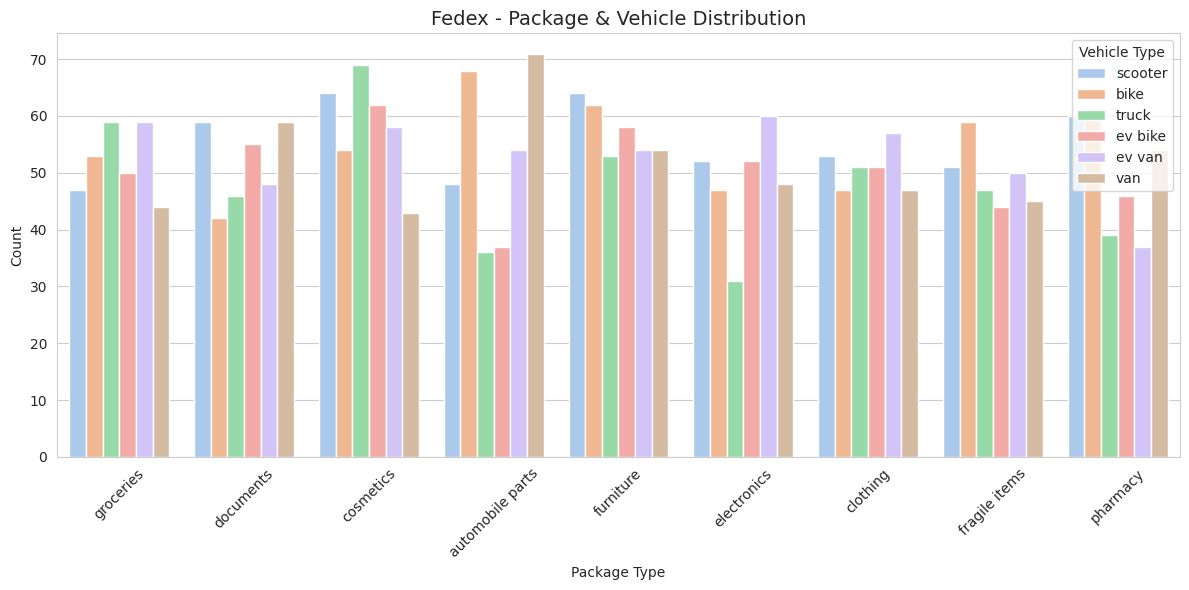

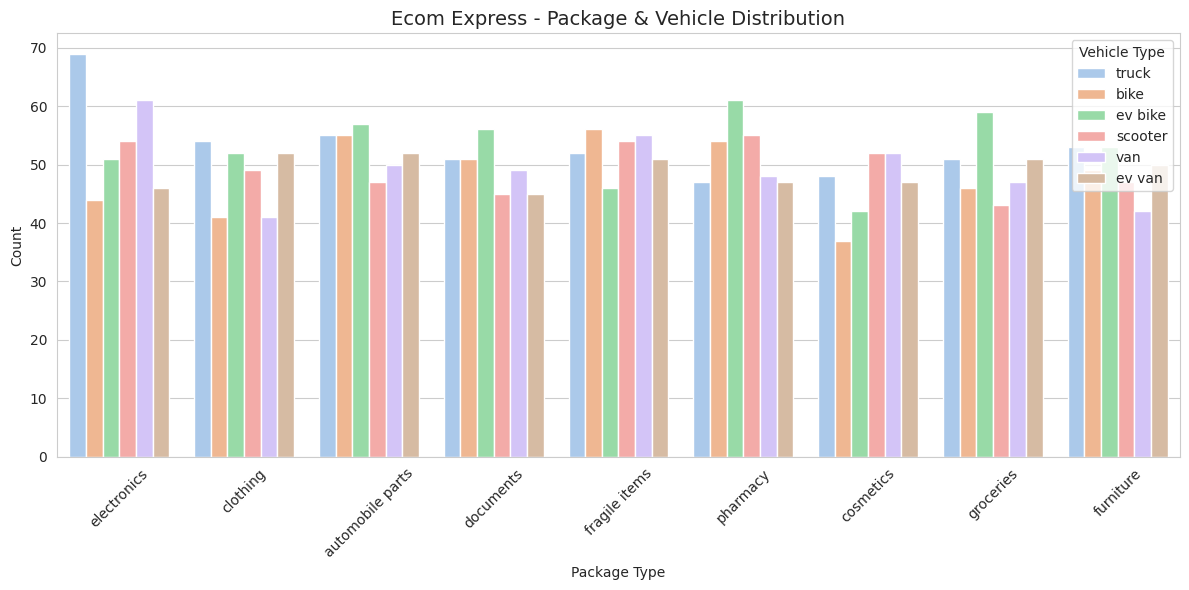

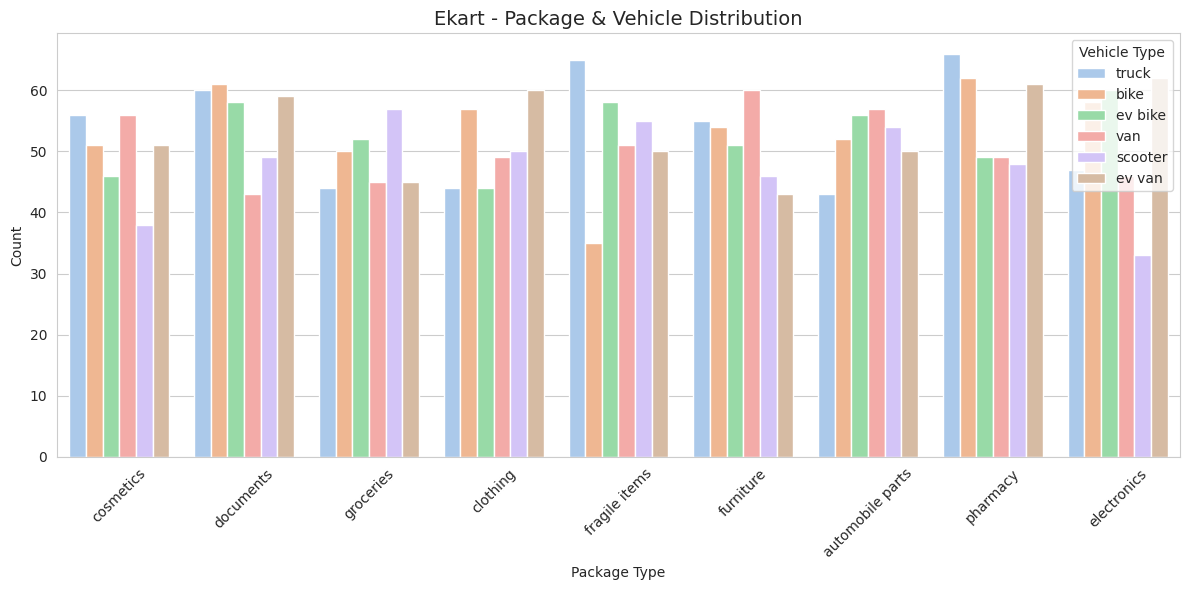

In [12]:
partners = df['delivery_partner'].unique()

for partner in partners:
    plt.figure(figsize=(12, 6))
    subset = df[df['delivery_partner'] == partner]
    
    sns.countplot(
        data=subset,
        x='package_type',
        hue='vehicle_type',
        palette='pastel'
    )
    
    plt.title(f'{partner.title()} - Package & Vehicle Distribution', fontsize=14)
    plt.xlabel('Package Type')
    plt.ylabel('Count')
    plt.legend(title='Vehicle Type', loc="upper right")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

## Interactive Bubble Chart Analysis 

In [13]:
df_grouped = df.groupby(['delivery_partner', 'package_type', 'vehicle_type']).size().reset_index(name='count')

fig = px.scatter(
    df_grouped,
    x="package_type",
    y="vehicle_type",
    size="count",
    color="vehicle_type",
    animation_frame="delivery_partner",
    hover_name="package_type",
    hover_data=["count"],
    size_max=35,
    width=1000,
    height=600,
    title="Delivery Analysis: Package vs Vehicle Types (Animated by Partner)",
    template="plotly_white"
)

fig.update_layout(
    xaxis=dict(title='Package Type', tickangle=-45),
    yaxis=dict(title='Vehicle Type'),
    margin=dict(l=50, r=50, t=50, b=100)
)

fig.show()

##  Numerical Feature Distributions

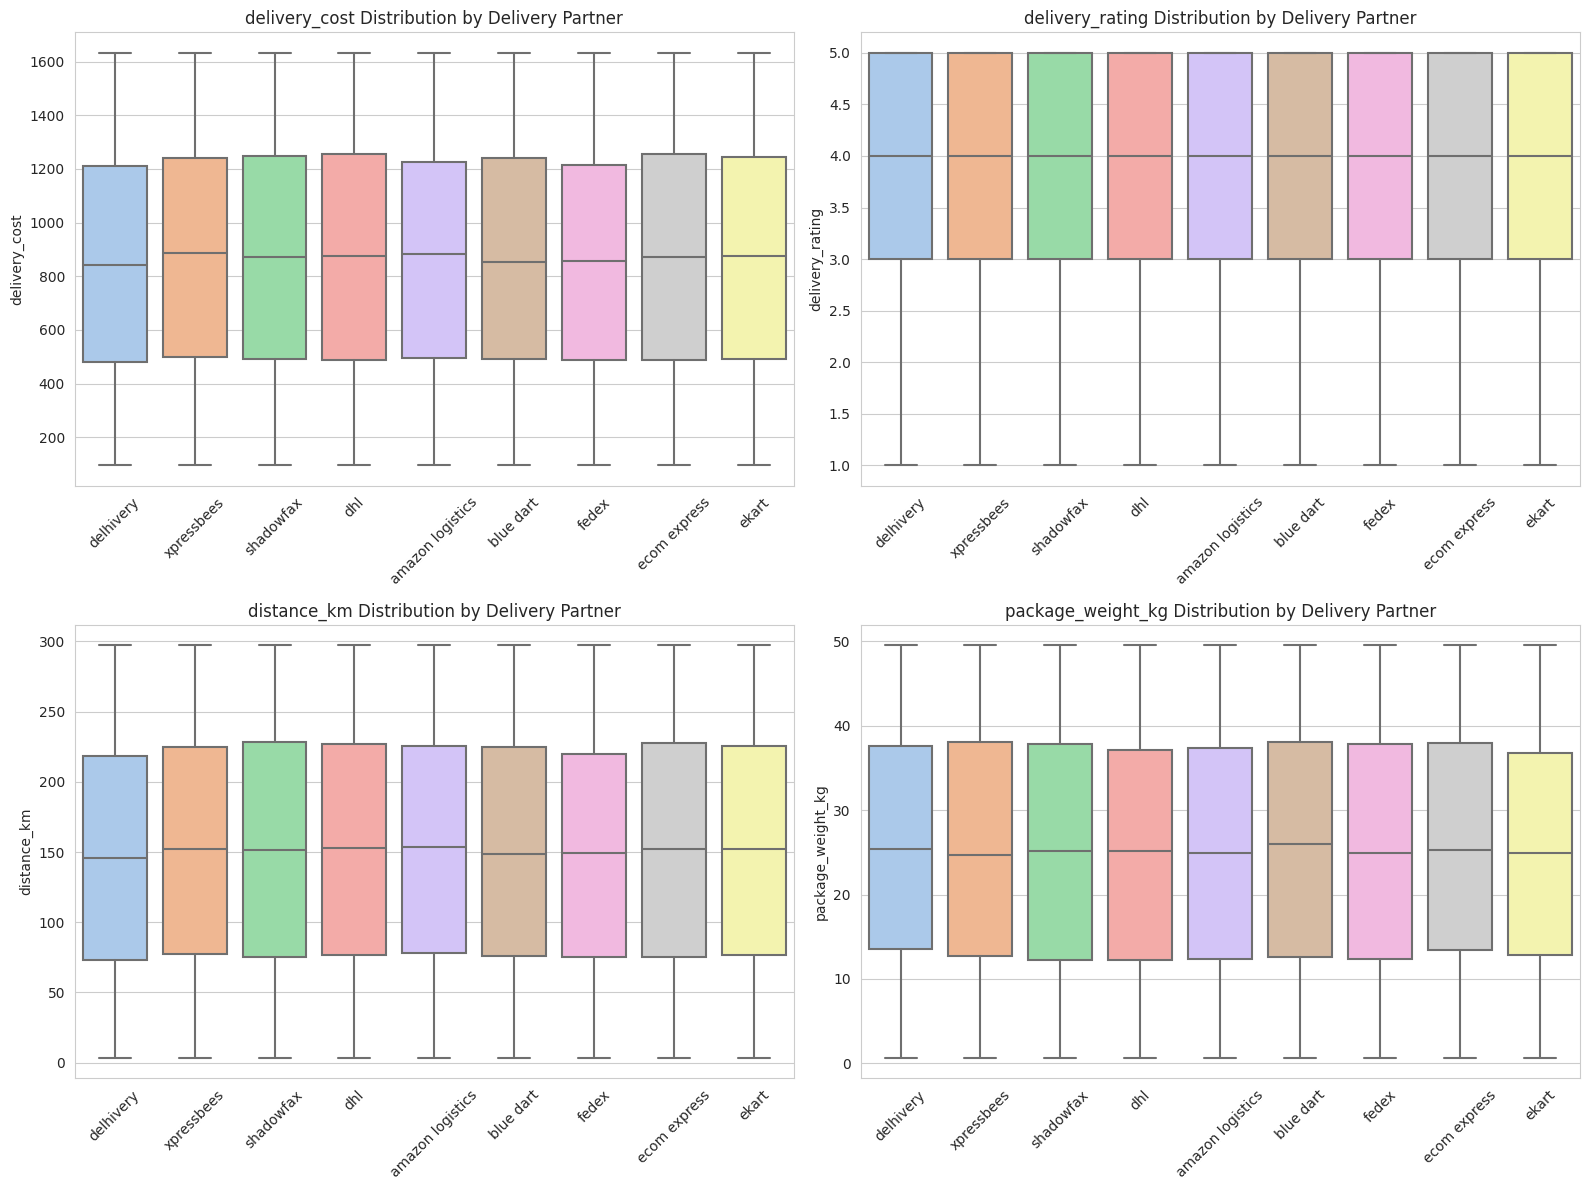

In [14]:
numeric_cols = ['delivery_cost', 'delivery_rating', 'distance_km', 'package_weight_kg']

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.boxplot(
        data=df,
        x='delivery_partner',
        y=col,
        ax=axes[i],
        palette='pastel'
    )
    axes[i].set_title(f'{col} Distribution by Delivery Partner', fontsize=12)
    axes[i].set_xlabel('')
    axes[i].set_ylabel(col)
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

**Insight:** As seen in the boxplots above, the metrics (cost, rating, distance, weight) are quite similarly distributed across different delivery partners, indicating a competitive market.

## Correlation Matrix

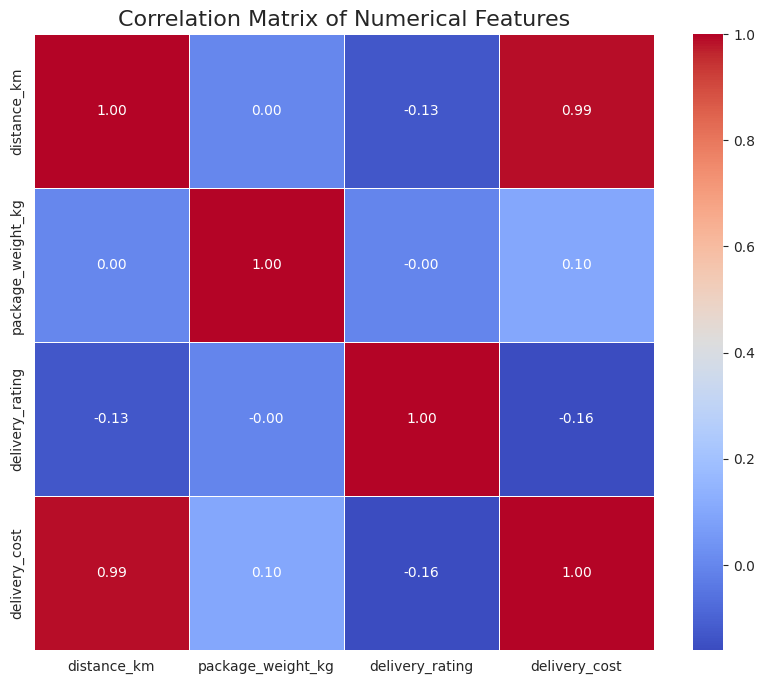

In [15]:
numeric_cols_df = df.select_dtypes(include=['float64', 'int64']).columns
correlation_matrix = df[numeric_cols_df].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Numerical Features', fontsize=16)
plt.show()

# Feature Engineering & Preprocessing
We will create a target variable rating_group by grouping the ratings into three categories:

0 -> Bad (1,2)

1 -> Average (3)

2 -> Good (4,5)

In [16]:
def group_rating(rating):
    if rating <= 2:
        return 0 # Bad
    elif rating == 3:
        return 1 # Average
    else:
        return 2 # Good

df['rating_group'] = df['delivery_rating'].apply(group_rating)

## Label Encoding for Categorical Variables

In [17]:
categorical_cols = ['delivery_partner', 'package_type', 'vehicle_type',
                    'delivery_mode', 'region', 'weather_condition',
                    'delivery_status']

le = LabelEncoder()
for col in categorical_cols:
    df[col] = le.fit_transform(df[col])

df.head()

,delivery_partner,package_type,vehicle_type,delivery_mode,region,weather_condition,distance_km,package_weight_kg,delivery_status,delivery_rating,delivery_cost,rating_group
0,2,0,0,1,4,0,297.0,46.96,1,3,1632.7206,1
1,8,2,2,0,0,1,89.6,47.39,1,5,640.1700,2
2,7,7,4,3,1,4,273.5,26.89,1,4,1448.1700,2
3,3,4,2,1,1,1,269.7,12.69,1,3,1486.5700,1
4,3,1,5,3,2,2,256.7,37.02,1,4,1394.5600,2


# Machine Learning Modeling

In [18]:
X = df.drop(["delivery_rating", "rating_group"], axis=1)
y = df['rating_group']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## LightGBM Classifier 

In [19]:

lgbm_model = LGBMClassifier(
    random_state=42,
    learning_rate=0.06,
    max_depth=10,
    num_leaves=100,
    class_weight='balanced',
    verbose=-1 
)

lgbm_model.fit(X_train, y_train)
y_pred_lgbm = lgbm_model.predict(X_test)

print("--- LightGBM Classification Report ---")
print(classification_report(y_test, y_pred_lgbm))

--- LightGBM Classification Report ---
              precision    recall  f1-score   support

           0       0.68      0.92      0.78       901
           1       0.26      0.07      0.11      1124
           2       0.81      0.95      0.87      2975

    accuracy                           0.74      5000
   macro avg       0.58      0.65      0.59      5000
weighted avg       0.66      0.74      0.69      5000



## XGBoost Classifier

In [20]:
sample_weights = compute_sample_weight(
    class_weight='balanced',
    y=y_train
)

xgb_model = XGBClassifier(
    objective='multi:softprob',
    num_class=3,
    random_state=42,
    eval_metric='mlogloss',
    use_label_encoder=False
)

xgb_model.fit(X_train, y_train, sample_weight=sample_weights)
y_pred_xgb = xgb_model.predict(X_test)

print("--- XGBoost Classification Report ---")
print(classification_report(y_test, y_pred_xgb, target_names=['Bad', 'Average', 'Good']))

--- XGBoost Classification Report ---
              precision    recall  f1-score   support

         Bad       0.69      0.86      0.76       901
     Average       0.26      0.13      0.18      1124
        Good       0.81      0.90      0.85      2975

    accuracy                           0.72      5000
   macro avg       0.59      0.63      0.60      5000
weighted avg       0.67      0.72      0.68      5000



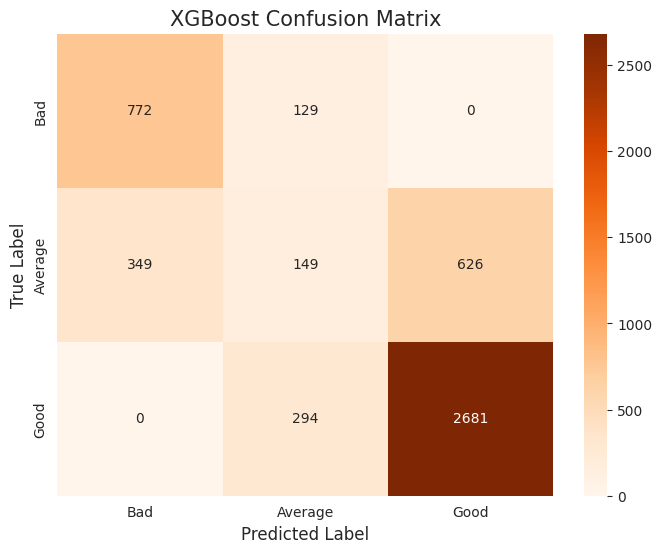

In [21]:
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred_xgb)

sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Bad', 'Average', 'Good'],
            yticklabels=['Bad', 'Average', 'Good'])

plt.title('XGBoost Confusion Matrix', fontsize=15)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.show()

# Conclusion

**EDA:** Showed uniform distribution among partners but varied relationships between vehicle and package types.

**Modeling:** Both LightGBM and XGBoost provided competitive results. Class weighting was crucial to handle imbalances in rating categories.
